# 1.1

### type - algorithm - metric
1. regression - linear regression - MAE*, MSE, R2
2. classification - logistic regression - F1*
3. regression - linear regression - MAE*
4. classification - logistic regression - recall*, precision, F1, confusion matrix
5. regression - linear regression - MAE 
6. classification - K-means - no match

# 1.2
1. زیرا این معیارها برای وقتی هستند که فاصله نتیجه پیش بینی شده را از نتیجه مورد انتظار میسنجیم و نتیجه ی مورد انتظار در در این الگوریتم تعریف نشده است.
2. the data is so imbalancedthat a model always predicting 'positive' could have high accuracy but that alone doesn't mean we have got the quality we're aiming for.
3. In a regression model the data is continous. In classification it's discrete. binary or multiclass we still know the exact outcome we're expecting. it's possible to compare it to a predicted outcome by distance. in the other case is not.

# 2.1

In [20]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [21]:
quiz_data = pd.DataFrame({
    "study_hours": [
        4.8, 11.4, 8.9, 7.4, 2.3, 2.3, 1.2, 10.5, 7.4, 8.6, 0.7, 11.7, 10.1, 2.9, 2.6, 2.6,
        4.0, 6.5, 5.5, 3.8, 7.5, 2.1, 3.9, 4.7, 5.7, 9.5, 2.8, 6.4, 7.3, 1.0, 7.5, 2.5,
        1.2, 11.4, 11.6, 9.8, 4.0, 1.6, 8.4, 5.6, 1.9, 6.2, 0.9, 11.0, 3.5, 8.1, 4.1, 6.5,
        6.8, 2.6, 11.7, 9.4, 11.3, 10.8, 7.4, 11.1, 1.5, 2.8, 1.0, 4.2
    ],
    "videos_watched": [
        15, 12, 17, 14, 20, 23, 24, 12, 8, 14, 12, 0, 24, 6, 8, 23, 0, 11, 7, 23, 10, 18, 16, 7,
        2, 2, 0, 4, 9, 6, 8, 6, 8, 7, 11, 1, 0, 15, 22, 22, 23, 4, 2, 11, 7, 21, 2, 0, 2, 4,
        14, 13, 2, 0, 4, 22, 13, 6, 8, 14
    ],
    "practice_solved": [
        14, 25, 12, 31, 38, 31, 3, 29, 36, 22, 38, 14, 28, 35, 12, 31, 6, 21, 27, 1, 5, 27, 27, 19,
        29, 10, 27, 24, 38, 32, 0, 26, 12, 2, 38, 5, 7, 26, 8, 36, 32, 23, 14, 31, 31, 23, 11, 38,
        1, 2, 36, 16, 1, 1, 27, 22, 36, 31, 32, 0
    ],
    "quiz_score": [
        59.7, 94.2, 82.2, 83.1, 72.2, 62.8, 43.3, 97.3, 78.1, 88.6, 61.2, 86.6, 97.9, 59.2, 43.3, 72.4,
        48.4, 74.1, 66.6, 54.6, 67.3, 55.2, 68.7, 54.5, 67.1, 69.7, 47.2, 62.9, 81.4, 50.7, 64.3, 53.8,
        44.5, 88.3, 100.0, 67.1, 36.4, 59.6, 85.4, 80.9, 68.6, 69.8, 35.0, 100.0, 60.6, 82.2, 50.8, 77.4,
        55.7, 32.3, 100.0, 77.8, 76.1, 74.3, 74.4, 100.0, 55.3, 56.6, 44.6, 47.0
    ]
})
#الف
X = quiz_data[["study_hours", "videos_watched", "practice_solved"]]
y = quiz_data["quiz_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#ب
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
#ج
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")
print(f"Mean Absolute Error: {mae:.2f}")


Mean Squared Error: 19.96
R-squared: 0.94
Mean Absolute Error: 3.56


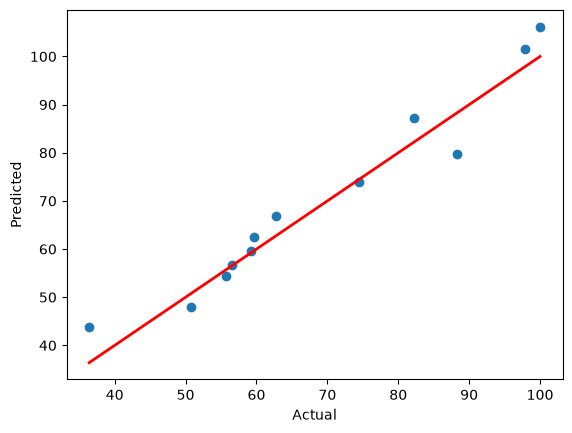

In [22]:
import matplotlib.pyplot as plt
#د
plt.scatter(y_test, y_pred)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], lw=2, color = 'red')
plt.show()

# 2.2

In [23]:
#هـ
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"Mean Squared Error: {mse:.2f}")
print(f"R-squared: {r2:.2f}")
print(f"Mean Absolute Error: {mae:.2f}")

coef = model.coef_
for i, feature in enumerate(X.columns):
    print(f"Coefficient for {feature}: {coef[i]:.4f}")

Mean Squared Error: 19.96
R-squared: 0.94
Mean Absolute Error: 3.56
Coefficient for study_hours: 4.5635
Coefficient for videos_watched: 0.7350
Coefficient for practice_solved: 0.5860


# 2.3
1. 'study hours' is the primary feature and yes it matches my observation
2. yes they are mostly near the line. if not they're outliers.
3. high r2 score is misleading as it checks in sample fit. it does garantee that the model is indeed a good fit for the current data set but we cannot say for sure that the model is gonna do well on unseen data based on this metric alone. Increasing variables can effectively increase r2 which makes the metric inreliable for measuring model quality.
4. as mentioned in the previous answer r2 increases when values increase.

# 3.1

In [24]:
import pandas as pd

gym_data = pd.DataFrame({
    "visits_per_month": [
        6,5,0,4,15,12,18,4,17,6,6,0,11,18,8,0,16,12,16,14,17,13,3,19,13,15,15,4,0,16,
        18,15,0,11,4,0,0,5,17,15,17,10,0,6,5,10,14,4,13,19,6,7,17,4,5,17,3,7,0,12,
        19,12,1,14,13,9,11,6,8,19,12,8,10,17,14,5,12,7,2,4,14,12,9,16,11,9,3,10,4,16
    ],
    "avg_session_min": [
        51.1,40.8,15.4,74.2,42.2,44.3,26.8,54.0,66.4,56.7,25.1,18.6,66.3,73.9,48.1,13.9,40.4,27.1,49.5,51.0,
        42.2,51.2,13.4,43.6,54.7,49.9,74.3,47.5,11.3,25.4,51.7,47.2,12.6,32.4,54.5,11.0,13.1,28.6,33.4,45.6,
        38.9,64.9,24.3,58.1,42.0,72.3,66.1,53.3,64.1,25.1,68.6,52.4,49.4,63.6,63.1,62.6,17.9,71.0,13.2,50.1,
        59.8,48.8,22.6,27.8,49.8,30.3,51.6,56.8,33.3,54.3,31.1,52.9,35.4,65.0,37.1,47.1,73.8,59.7,12.0,59.5,
        72.2,52.2,62.6,51.2,37.1,46.4,16.8,39.4,37.3,42.7
    ],
    "days_since_last_visit": [
        8,10,21,1,10,11,8,1,14,3,7,41,1,6,14,20,8,7,12,14,2,14,23,12,7,4,10,5,46,4,
        11,4,58,11,10,26,49,4,14,5,13,5,43,13,10,7,1,5,2,13,14,11,1,12,3,7,27,3,25,9,
        1,5,27,11,8,4,9,0,9,5,12,10,5,1,4,2,12,10,55,10,8,14,13,8,3,11,34,12,6,8
    ],
    "has_personal_trainer": [
        1,1,0,1,1,0,1,1,1,1,1,0,1,0,1,0,1,1,0,1,1,1,1,1,1,1,0,1,0,1,0,0,0,0,0,1,0,1,0,1,0,0,0,0,0,1,0,1,0,1,1,1,1,
        1,0,1,0,1,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,1,1,0,1,0,1,0,1,1,0,1,1,0,1,1,0,0
    ],
    "churned": [
        0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,1,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,
        0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0
    ]
})


In [25]:
#الف
gym_data.head()

,visits_per_month,avg_session_min,days_since_last_visit,has_personal_trainer,churned
0,6,51.1,8,1,0
1,5,40.8,10,1,0
2,0,15.4,21,0,1
3,4,74.2,1,1,0
4,15,42.2,10,1,0


In [26]:
gym_data['churned'].value_counts()

churned
0    76
1    14
Name: count, dtype: int64

# 2.2

In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression  
from sklearn.metrics import f1_score, confusion_matrix, accuracy_score, precision_score, recall_score
#ب
X = gym_data[['visits_per_month', 'avg_session_min', 'days_since_last_visit', 'has_personal_trainer']]
y = gym_data['churned']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    random_state=42,
    stratify=y,
    test_size=0.2
)
#ج
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_train_scaled)       
#د
recall = recall_score(y_train, y_pred)
precision = precision_score(y_train, y_pred)
accuracy = accuracy_score(y_train, y_pred)
f1 = f1_score(y_train, y_pred)

print(f"Recall: {recall:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Accuracy: {accuracy:.2f}")
print(f"F1-Score: {f1:.2f}")

conf_m = confusion_matrix(y_train, y_pred)
print("Confusion Matrix:", conf_m, sep="\n")

Recall: 1.00
Precision: 1.00
Accuracy: 1.00
F1-Score: 1.00
Confusion Matrix:
[[61  0]
 [ 0 11]]


In [28]:
y_pred = model.predict(X_test_scaled)       
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Recall: {recall:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Accuracy: {accuracy:.2f}")
print(f"F1-Score: {f1:.2f}")

conf_m = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:", conf_m, sep="\n")

Recall: 1.00
Precision: 1.00
Accuracy: 1.00
F1-Score: 1.00
Confusion Matrix:
[[15  0]
 [ 0  3]]


TP = 3
TN = 15
FN = 0
FP = 0

# 3.3

الف) churned is imbalanced because of the output of value_counts(). if a model always predicted '0' in this scenario it could easily acheive 84% accuracy.\
ب) accuracy is not promising because the dataset is split prefectly and recall is more important because we care about churned users. if we fail to detect a leaving user we lose them forever but if we falsely predict a staying one as leaving it won't cause that big of a damage \
ج) well I think that if they are leaving it's important to get them back but with this new condition we have to care about our FPs too because a lot of false positives can lead to a lot of false discount hand outs that aren't really beneficial. (the number is still small and worth it compared to losing a customer in my opinion).

In [29]:
#د
y_pred = (model.predict_proba(X_test_scaled)[:, 1] >= 0.3).astype(int)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Recall: {recall:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Accuracy: {accuracy:.2f}")
print(f"F1-Score: {f1:.2f}")

conf_m = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:", conf_m, sep="\n")

Recall: 1.00
Precision: 1.00
Accuracy: 1.00
F1-Score: 1.00
Confusion Matrix:
[[15  0]
 [ 0  3]]


### ***rewritten without the obvious feature

In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression  
from sklearn.metrics import f1_score, confusion_matrix, accuracy_score, precision_score, recall_score
#ب
X = gym_data[['visits_per_month', 'avg_session_min', 'has_personal_trainer']]
y = gym_data['churned']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    random_state=42,
    stratify=y,
    test_size=0.2
)
#ج
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_train_scaled)       
#د
recall = recall_score(y_train, y_pred)
precision = precision_score(y_train, y_pred)
accuracy = accuracy_score(y_train, y_pred)
f1 = f1_score(y_train, y_pred)

print(f"Recall: {recall:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Accuracy: {accuracy:.2f}")
print(f"F1-Score: {f1:.2f}")

conf_m = confusion_matrix(y_train, y_pred)
print("Confusion Matrix:", conf_m, sep="\n")

Recall: 1.00
Precision: 1.00
Accuracy: 1.00
F1-Score: 1.00
Confusion Matrix:
[[61  0]
 [ 0 11]]


In [31]:
y_pred = (model.predict_proba(X_test_scaled)[:, 1] >= 0.3).astype(int)
recall = recall_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Recall: {recall:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Accuracy: {accuracy:.2f}")
print(f"F1-Score: {f1:.2f}")

conf_m = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:", conf_m, sep="\n")

Recall: 1.00
Precision: 0.75
Accuracy: 0.94
F1-Score: 0.86
Confusion Matrix:
[[14  1]
 [ 0  3]]


#د we expect recall to be bigger because our predicted positives are increased and we're agreeing to see more FP and less FN.\
but precision becomes less because it now has many positive predictions that are actually not positive.

# 4.1

In [32]:
import pandas as pd

flight_data = pd.DataFrame({
    "days_before_flight": [
        26, 64, 81, 82, 56, 14, 77, 34, 72, 83, 25, 49, 33, 46, 5, 35, 13, 2, 75, 38,
        85, 82, 25, 18, 68, 71, 44, 65, 80, 24, 28, 71, 11, 58, 28, 45, 15, 8, 56, 80,
        65, 41, 28, 6, 54, 72, 51, 60, 2, 4, 9, 88, 82, 69, 73
    ],
    "distance_km": [
        575, 2245, 1234, 3510, 2458, 1752, 564, 1229, 685, 1291, 4245, 718, 319, 3456, 2142,
        743, 793, 1140, 1362, 2259, 419, 4258, 4171, 3104, 3216, 3504, 2533, 2669, 2088, 4486,
        930, 4032, 662, 3818, 4016, 3190, 4378, 1985, 1231, 2813, 2866, 4244, 2077, 614, 3949,
        1424, 4340, 1105, 1929, 2600, 3550, 4009, 2305, 2051, 2358
    ],
    "num_stops": [
        0, 1, 0, 1, 0, 0, 2, 2, 2, 0, 0, 2, 0, 1, 1, 1, 0, 1, 2, 2,
        2, 2, 0, 1, 2, 2, 0, 0, 2, 1, 1, 2, 0, 1, 1, 2, 2, 1, 2, 2,
        1, 1, 0, 2, 1, 2, 1, 0, 1, 0, 2, 0, 2, 2, 1
    ],
    "ticket_price_usd": [
        335, 380, 275, 391, 458, 431, 61, 331, 133, 233, 683, 214, 308, 506, 476,
        298, 402, 480, 162, 390, 63, 425, 705, 569, 368, 400, 474, 375, 233, 703,
        354, 443, 380, 492, 571, 475, 663, 495, 207, 287, 401, 595, 453, 357, 544,
        189, 552, 254, 476, 609, 611, 456, 224, 246, 315
    ]
})


In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

X = flight_data[['days_before_flight', 'distance_km', 'num_stops']]
y = flight_data['ticket_price_usd']

X_train, X_test, y_train, y_test = train_test_split(
    X,y,
    random_state=42,
    test_size=0.2
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = KNeighborsRegressor(n_neighbors=5)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)       
#ج
MSE = mean_squared_error(y_test, y_pred)
MAE = mean_absolute_error(y_test, y_pred)
R2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {MSE:.2f}")
print(f"Mean Absolute Error: {MAE:.2f}")
print(f"R-squared: {R2:.2f}")

Mean Squared Error: 2498.65
Mean Absolute Error: 34.31
R-squared: 0.79


In [34]:
def model_train(model):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    return y_pred

def calculate_r2(model):
    y_pred = model_train(model)
    R2 = r2_score(y_test, y_pred)
    return R2

for i in [1,3,5,7,9,15]:
    r2 = calculate_r2(KNeighborsRegressor(n_neighbors=i))
    print(f"R-squared for {i} neighbor: {r2:.4f}")

R-squared for 1 neighbor: 0.7056
R-squared for 3 neighbor: 0.7692
R-squared for 5 neighbor: 0.7947
R-squared for 7 neighbor: 0.7622
R-squared for 9 neighbor: 0.8540
R-squared for 15 neighbor: 0.7304


In [35]:
sample_data = pd.DataFrame({
    "days_before_flight": [20],
    "distance_km": [2000],
    "num_stops": [1]
})

In [36]:
def predict_sample(model):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(scaler.transform(sample_data))
    return y_pred

for i in [1,3,5,7,9,15]:
    y_pred_sample = predict_sample(KNeighborsRegressor(n_neighbors=i))
    print(f"Predicted ticket price for {i} neighbors: ${y_pred_sample[0]:.2f}")


Predicted ticket price for 1 neighbors: $495.00
Predicted ticket price for 3 neighbors: $482.33
Predicted ticket price for 5 neighbors: $474.00
Predicted ticket price for 7 neighbors: $449.71
Predicted ticket price for 9 neighbors: $436.89
Predicted ticket price for 15 neighbors: $442.13


# 4.2

In [37]:
def calculate_metrics(model):
    y_pred = model_train(model)
    mse = mean_squared_error(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    R2 = r2_score(y_test, y_pred)
    return mse, mae, R2
for i in [1,3,5,7,9,15]:
    mse, mae, r2 = calculate_metrics(KNeighborsRegressor(n_neighbors=i))
    print(f"Metrics for {i} neighbors: MSE={mse:.2f} | MAE={mae:.2f} | R2={r2:.2f}")

Metrics for 1 neighbors: MSE=3583.00 | MAE=44.27 | R2=0.71
Metrics for 3 neighbors: MSE=2809.54 | MAE=43.27 | R2=0.77
Metrics for 5 neighbors: MSE=2498.65 | MAE=34.31 | R2=0.79
Metrics for 7 neighbors: MSE=2894.19 | MAE=44.49 | R2=0.76
Metrics for 9 neighbors: MSE=1776.63 | MAE=31.88 | R2=0.85
Metrics for 15 neighbors: MSE=3281.68 | MAE=51.07 | R2=0.73


# 4.3
الف) it reverses after 15 neighbors
ب) in k=1 model learns the noises. in k=dataset there's nothing to be learned. prediction for all is the mean of the entire data set.\
ج) the huge difference in the numbers makes the model classify based on those features which isn't what we intended to do.\
د) knn is lazy because it simply stores the data in training phase and saves the computation for prediction time.